<a href="https://colab.research.google.com/github/nusaibuhh/daily-git/blob/main/ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Linear Regression

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [ ]:
df = pd.read_csv("/content/homeprices - Sheet1.csv")
df

,Area,Price
0,2600,55000
1,3000,56500
2,3200,61000
3,3600,68000
4,4000,72500


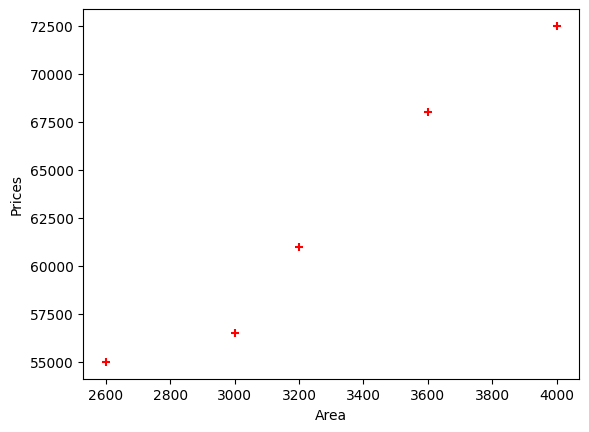

In [ ]:
%matplotlib inline
plt.xlabel('Area')
plt.ylabel('Prices')
plt.scatter(df.Area, df.Price, color='red', marker='+')


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(df[['Area']], df.Price)

LinearRegression()

In [ ]:
reg.predict([[3300]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([62871.57534247])

In [ ]:
#reg.coef_
reg.intercept_

np.float64(18061.64383561643)

In [ ]:
d = pd.DataFrame(
    {'Area' : [1000, 1500, 2300, 3540, 4120]},
    index = [1,2,3,4,5]
)
d

,Area
1,1000
2,1500
3,2300
4,3540
5,4120


In [ ]:
p = reg.predict(d)
d['Prices'] = p
d

,Area,Prices
1,1000,31640.410959
2,1500,38429.794521
3,2300,49292.808219
4,3540,66130.479452
5,4120,74006.164384


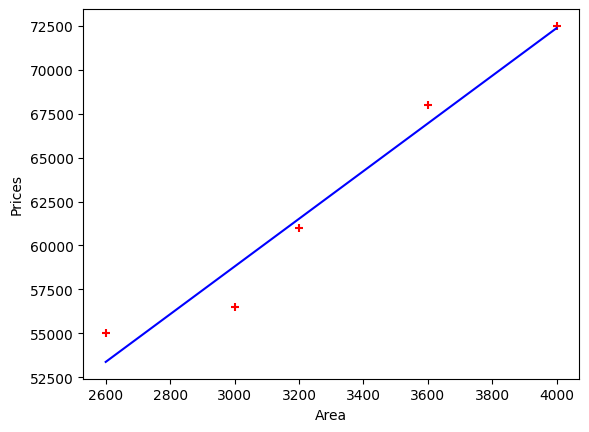

In [ ]:
%matplotlib inline
plt.xlabel('Area')
plt.ylabel('Prices')
plt.scatter(df.Area, df.Price, color='red', marker='+')
plt.plot(df.Area, reg.predict(df[['Area']]), color='blue')

# Multivariate Regression

In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model

In [ ]:
df = pd.DataFrame(
    {'Area' : [1000, 1500, 2300, 3540, 4120],
     'Bedrooms' : [3, 4, np.nan, 3, 5],
     'Age' : [20, 15, 18, 30, 8],
     'price': [5500, 5650, 6100, 5950, 7600]},
    index = [1,2,3,4,5]
)
df

,Area,Bedrooms,Age,price
1,1000,3.0,20,5500
2,1500,4.0,15,5650
3,2300,NaN,18,6100
4,3540,3.0,30,5950
5,4120,5.0,8,7600


In [ ]:
import math
median_bed =  math.floor(df.Bedrooms.median())
median_bed

3

In [ ]:
df['Bedrooms'] = df['Bedrooms'].fillna(median_bed)
df

,Area,Bedrooms,Age,price
1,1000,3.0,20,5500
2,1500,4.0,15,5650
3,2300,3.0,18,6100
4,3540,3.0,30,5950
5,4120,5.0,8,7600


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(df[['Area', 'Bedrooms', 'Age']], df.price)

LinearRegression()

In [ ]:
reg.coef_

array([   0.54494122, -207.05292815,  -76.22129008])

In [ ]:
reg.intercept_

np.float64(6934.624498172715)

In [ ]:
reg.predict([[3000,3,15]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([6804.97002538])

Practice

In [ ]:
d = pd.DataFrame(
    {'Experience' : [np.nan, np.nan, 'Five', 'Two', 'Seven', 'Three', 'Ten', 'Eleven'],
     'test_score' : [8, 8, 6, 10, 9, 7, np.nan, 7],
     'interview_score' : [9, 6, 7, 10, 6, 10, 7, 8],
     'salary': [5000, 4500, 6000, 6550, 7000, 6200, 7200, 8000]},
    index = [1,2,3,4,5,6,7,8]
)
d

,Experience,test_score,interview_score,salary
1,NaN,8.0,9,5000
2,NaN,8.0,6,4500
3,Five,6.0,7,6000
4,Two,10.0,10,6550
5,Seven,9.0,6,7000
6,Three,7.0,10,6200
7,Ten,NaN,7,7200
8,Eleven,7.0,8,8000


In [ ]:
!pip install word2number

  Preparing metadata (setup.py) ... done
  Created wheel for word2number: filename=word2number-1.1-py3-none-any.whl size=5657 sha256=3aa08bb5d45716df5d94ebd8386ccc3c93fba6b78755d1fb25977f4a8c6118b2
  Stored in directory: /root/.cache/pip/wheels/aa/2b/71/ede4a3c3520a8374778c16c345e0e78e25d1ffe38f4c5c1e8a
Successfully built word2number


In [ ]:
from word2number import w2n

# Example usage:
print(w2n.word_to_num("five"))
print(w2n.word_to_num("eleven"))

5
11


In [ ]:
from word2number import w2n

# Fill NaN values in Experience with 'zero'
d['Experience'] = d['Experience'].fillna('zero')

# Ensure all values are converted to string before applying word_to_num
d['Experience'] = d['Experience'].astype(str).apply(w2n.word_to_num)

d

,Experience,test_score,interview_score,salary
1,0,8.0,9,5000
2,0,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,NaN,7,7200
8,11,7.0,8,8000


In [ ]:
import math
median_exp =  math.floor(d.Experience.median())
median_exp

4

In [ ]:
# Replace 0 values in the Experience column with the calculated median
d['Experience'] = d['Experience'].replace(0, median_exp)
d

,Experience,test_score,interview_score,salary
1,4,8.0,9,5000
2,4,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,NaN,7,7200
8,11,7.0,8,8000


In [ ]:
median_score = math.floor(d.test_score.median())
median_score
d['test_score'] = d['test_score'].fillna(median_score)
d

,Experience,test_score,interview_score,salary
1,4,8.0,9,5000
2,4,8.0,6,4500
3,5,6.0,7,6000
4,2,10.0,10,6550
5,7,9.0,6,7000
6,3,7.0,10,6200
7,10,8.0,7,7200
8,11,7.0,8,8000


In [ ]:
reg = linear_model.LinearRegression()
reg.fit(d[['Experience','test_score','interview_score']], d.salary)

LinearRegression()

In [ ]:
reg.predict([[12,10,10]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([9508.03081147])

# Gradient Descent, Cost Function

mse = 1/n * sum of ((y - y-pred)**2)